# Network Intrusion Detection on NSL-KDD: Five Classifiers Compared

**Task:** binary classification of network connections as *normal* or *attack* using the NSL-KDD dataset, with five models (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM) and six metrics (Accuracy, AUC, Precision, Recall, F1, MCC).

**Protocol:** train on `KDDTrain+` (125,973 records), evaluate on the official hold-out `KDDTest+` (22,544 records).

## 1. Setup

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
SLOW_TRAIN_SIZE = 20000      # KNN and SVM are trained on a stratified subsample of this size
os.makedirs("model", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def find_file(*candidates):
    for c in candidates:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"None of {candidates} found. Download NSL-KDD and place the files next to this notebook.")

TRAIN_PATH = find_file("data_raw/KDDTrain+.txt", "KDDTrain+.txt", "KDDTrain_.txt")
TEST_PATH  = find_file("data_raw/KDDTest+.txt",  "KDDTest+.txt",  "KDDTest_.txt")
TRAIN_PATH, TEST_PATH

('data_raw/KDDTrain+.txt', 'data_raw/KDDTest+.txt')

## 2. Dataset description and loading

NSL-KDD (Tavallaee et al., 2009) is a cleaned version of KDD Cup 99 with duplicate records removed. Each record is one network connection described by **41 features**: 3 categorical (`protocol_type`, `service`, `flag`) and 38 numeric (durations, byte counts, error rates, host-based traffic statistics). Source files: `KDDTrain+.txt` and `KDDTest+.txt` (tab-separated, no header).

Notes on the files used here:
- The training file includes the specific attack name and a difficulty score. The test file has only a binary `Attack`/`Normal` label, so the problem is framed as **binary classification** (0 = normal, 1 = attack).
- The difficulty column is dropped; it is not a network feature.

In [2]:
COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate",
]
CATEGORICAL = ["protocol_type", "service", "flag"]
NUMERIC = [c for c in COLUMNS if c not in CATEGORICAL]

def load_nsl_kdd(path):
    """Load a raw NSL-KDD file (tab or comma separated, with or without header)."""
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        first = f.readline()
    sep = "\t" if "\t" in first else ","
    has_header = first.strip().lower().startswith("duration")
    df = pd.read_csv(path, sep=sep, header=0 if has_header else None)
    if has_header:
        df.columns = [str(c).strip().lower() for c in df.columns]
        df = df.rename(columns={"class": "label", "attack": "label"})
    else:
        extra = ["label", "difficulty"][: df.shape[1] - len(COLUMNS)]
        df.columns = COLUMNS + extra
    df = df.drop(columns=[c for c in ["difficulty", "difficulty_level"] if c in df.columns])
    df["label"] = df["label"].astype(str).str.strip().str.lower()
    df["target"] = (df["label"] != "normal").astype(int)     # 1 = attack
    return df

train, test = load_nsl_kdd(TRAIN_PATH), load_nsl_kdd(TEST_PATH)
print(f"Train: {train.shape[0]:,} rows | Test: {test.shape[0]:,} rows | Features: {len(COLUMNS)} "
      f"({len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical)")
print("Missing values  train/test:", int(train.isna().sum().sum()), "/", int(test.isna().sum().sum()))
print("Duplicate rows  train/test:", int(train.duplicated().sum()), "/", int(test.duplicated().sum()))
train.head()

Train: 125,973 rows | Test: 22,544 rows | Features: 41 (38 numeric + 3 categorical)
Missing values  train/test: 0 / 0
Duplicate rows  train/test: 0 / 3


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,target
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,0
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,0
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,0
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,0


### 2.1 Class balance and attack types

        Train (KDDTrain+)  Test (KDDTest+)
Normal             0.5346           0.4308
Attack             0.4654           0.5692


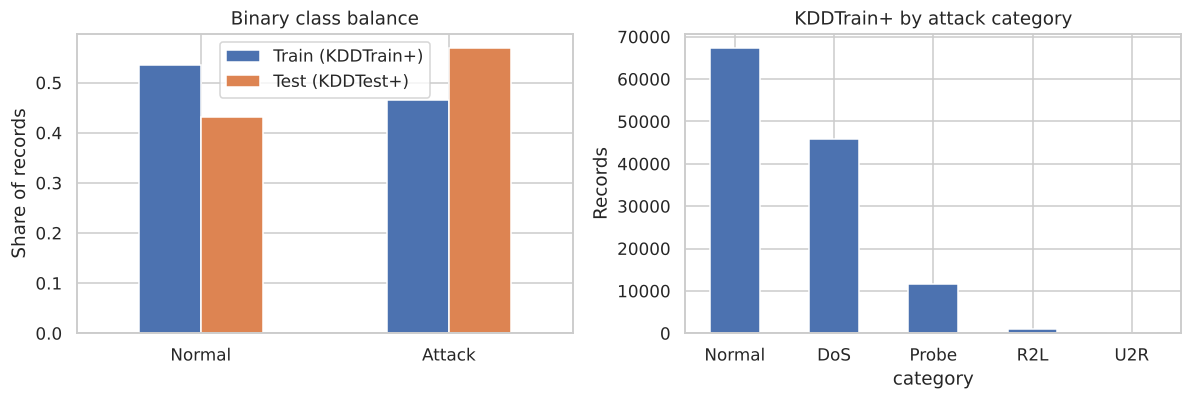

In [3]:
ATTACK_GROUP = {}
for g, names in {
    "DoS":   ["back", "land", "neptune", "pod", "smurf", "teardrop"],
    "Probe": ["satan", "ipsweep", "nmap", "portsweep"],
    "R2L":   ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy"],
    "U2R":   ["buffer_overflow", "loadmodule", "rootkit", "perl"],
}.items():
    for n in names:
        ATTACK_GROUP[n] = g
train["category"] = train["label"].map(lambda x: "Normal" if x == "normal" else ATTACK_GROUP.get(x, "Other"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bal = pd.DataFrame({"Train (KDDTrain+)": train["target"].value_counts(normalize=True).sort_index(),
                    "Test (KDDTest+)":  test["target"].value_counts(normalize=True).sort_index()})
bal.index = ["Normal", "Attack"]
bal.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Binary class balance"); axes[0].set_ylabel("Share of records")
train["category"].value_counts().plot(kind="bar", ax=axes[1], rot=0, color="#4c72b0")
axes[1].set_title("KDDTrain+ by attack category"); axes[1].set_ylabel("Records")
plt.tight_layout(); plt.savefig("figures/class_distribution.png", dpi=150); plt.show()
print(bal.round(4).to_string())

## 3. Preprocessing

- **Numeric features** (38): standardised with `StandardScaler` (important for Logistic Regression, KNN and SVM, which are scale-sensitive).
- **Categorical features** (3): one-hot encoded with `OneHotEncoder(handle_unknown="ignore")`, giving 122 model inputs in total.
- The preprocessor is **fit on the training data only** and then applied to the test data, so no test information leaks into training.
- Test-set service values that never appear in training (for example the anonymised value `Attack4` on 306 test records) are encoded as all zeros by `handle_unknown="ignore"`, so they cannot leak the label.
- **KNN and SVM** do not scale well to 126k rows, so they are trained on a stratified 20,000-row subsample of the training set. The other three models use all training rows. All five are evaluated on the full `KDDTest+`.

In [4]:
def build_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])

X_train, y_train = train[COLUMNS], train["target"]
X_test,  y_test  = test[COLUMNS],  test["target"]

pre = build_preprocessor()
Xtr = pre.fit_transform(X_train)
Xte = pre.transform(X_test)
print("Encoded feature count:", Xtr.shape[1])
print("Unseen test services (encoded as zeros):", sorted(set(X_test.service) - set(X_train.service)),
      "| rows:", int((~X_test.service.isin(set(X_train.service))).sum()))

Xtr_s, _, ytr_s, _ = train_test_split(Xtr, y_train, train_size=SLOW_TRAIN_SIZE,
                                      stratify=y_train, random_state=RANDOM_STATE)
print("Subsample for KNN/SVM:", Xtr_s.shape, "| attack share:", round(ytr_s.mean(), 4))

Encoded feature count: 122
Unseen test services (encoded as zeros): ['Attack4'] | rows: 306
Subsample for KNN/SVM: (20000, 122) | attack share: 0.4654


## 4. Models and evaluation

Five classifiers are trained on the same data. AUC is computed from continuous scores (`predict_proba` where available, `decision_function` for the SVM); every other metric uses the hard class predictions. **Precision, Recall and F1 are reported for the attack class (class 1).**

In [5]:
models = {
    "Logistic Regression":    (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), False),
    "Decision Tree":          (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    "KNN":                    (KNeighborsClassifier(n_neighbors=5, n_jobs=-1), True),
    "Naive Bayes":            (GaussianNB(), False),
    "Support Vector Machine": (SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE), True),
}

def attack_score(m, X):
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)

rows, preds, scores, fitted = [], {}, {}, {}
for name, (m, slow) in models.items():
    Xf, yf = (Xtr_s, ytr_s) if slow else (Xtr, y_train)
    t0 = time.time()
    m.fit(Xf, yf)
    fit_s = time.time() - t0
    preds[name], scores[name], fitted[name] = m.predict(Xte), attack_score(m, Xte), m
    rows.append({
        "ML Model Name": name,
        "Accuracy":  accuracy_score(y_test, preds[name]),
        "AUC":       roc_auc_score(y_test, scores[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall":    recall_score(y_test, preds[name]),
        "F1":        f1_score(y_test, preds[name]),
        "MCC":       matthews_corrcoef(y_test, preds[name]),
    })
    print(f"{name:24s} trained on {len(yf):>7,} rows in {fit_s:5.1f}s")

results = pd.DataFrame(rows).round(4)
results.set_index("ML Model Name")

Logistic Regression      trained on 125,973 rows in   3.7s
Decision Tree            trained on 125,973 rows in   1.5s
KNN                      trained on  20,000 rows in   0.0s
Naive Bayes              trained on 125,973 rows in   0.2s
Support Vector Machine   trained on  20,000 rows in   2.4s


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7522,0.7928,0.9171,0.6207,0.7404,0.5562
Decision Tree,0.7854,0.8079,0.9648,0.6467,0.7743,0.6274
KNN,0.7630,0.8179,0.9672,0.6042,0.7438,0.5970
Naive Bayes,0.5559,0.7989,0.9764,0.2253,0.3661,0.3197
Support Vector Machine,0.7740,0.8882,0.9598,0.6294,0.7603,0.6087


### 4.1 Comparison table

In [6]:
display_table = results.set_index("ML Model Name")
print("Best model per metric:")
print(display_table.idxmax().to_string())
display_table.style.highlight_max(axis=0, color="#cfe8cf").format("{:.4f}")

Best model per metric:
Accuracy              Decision Tree
AUC          Support Vector Machine
Precision               Naive Bayes
Recall                Decision Tree
F1                    Decision Tree
MCC                   Decision Tree


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7522,0.7928,0.9171,0.6207,0.7404,0.5562
Decision Tree,0.7854,0.8079,0.9648,0.6467,0.7743,0.6274
KNN,0.7630,0.8179,0.9672,0.6042,0.7438,0.5970
Naive Bayes,0.5559,0.7989,0.9764,0.2253,0.3661,0.3197
Support Vector Machine,0.7740,0.8882,0.9598,0.6294,0.7603,0.6087


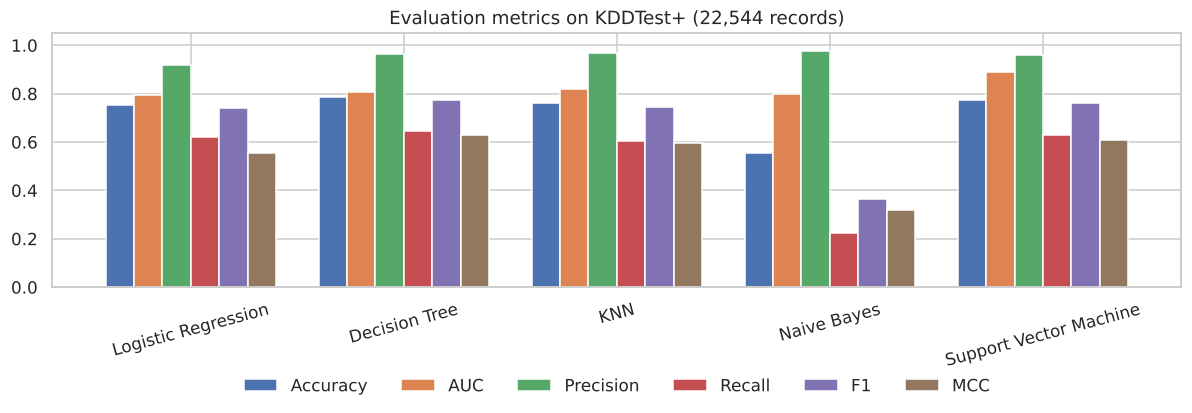

In [7]:
ax = results.set_index("ML Model Name").plot(kind="bar", figsize=(11, 4.2), rot=15, width=0.8)
ax.set_ylim(0, 1.05); ax.set_title("Evaluation metrics on KDDTest+ (22,544 records)")
ax.set_xlabel("")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.30), frameon=False)
plt.tight_layout(); plt.savefig("figures/metrics_comparison.png", dpi=150); plt.show()

### 4.2 ROC curves

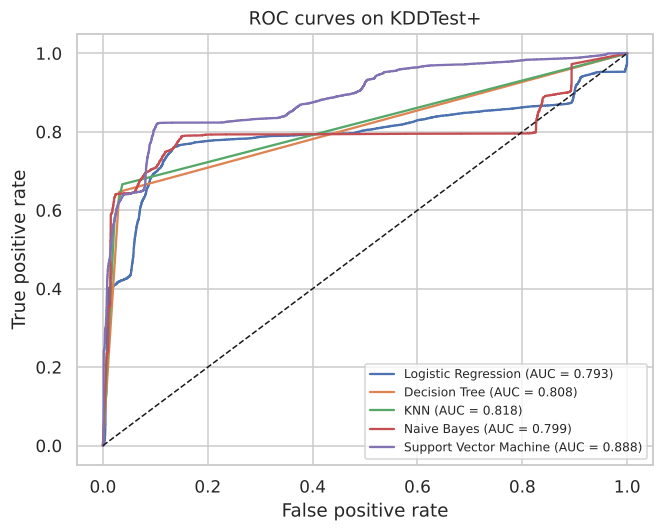

In [8]:
plt.figure(figsize=(6.2, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, scores[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on KDDTest+"); plt.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("figures/roc_curves.png", dpi=150); plt.show()

### 4.3 Confusion matrices

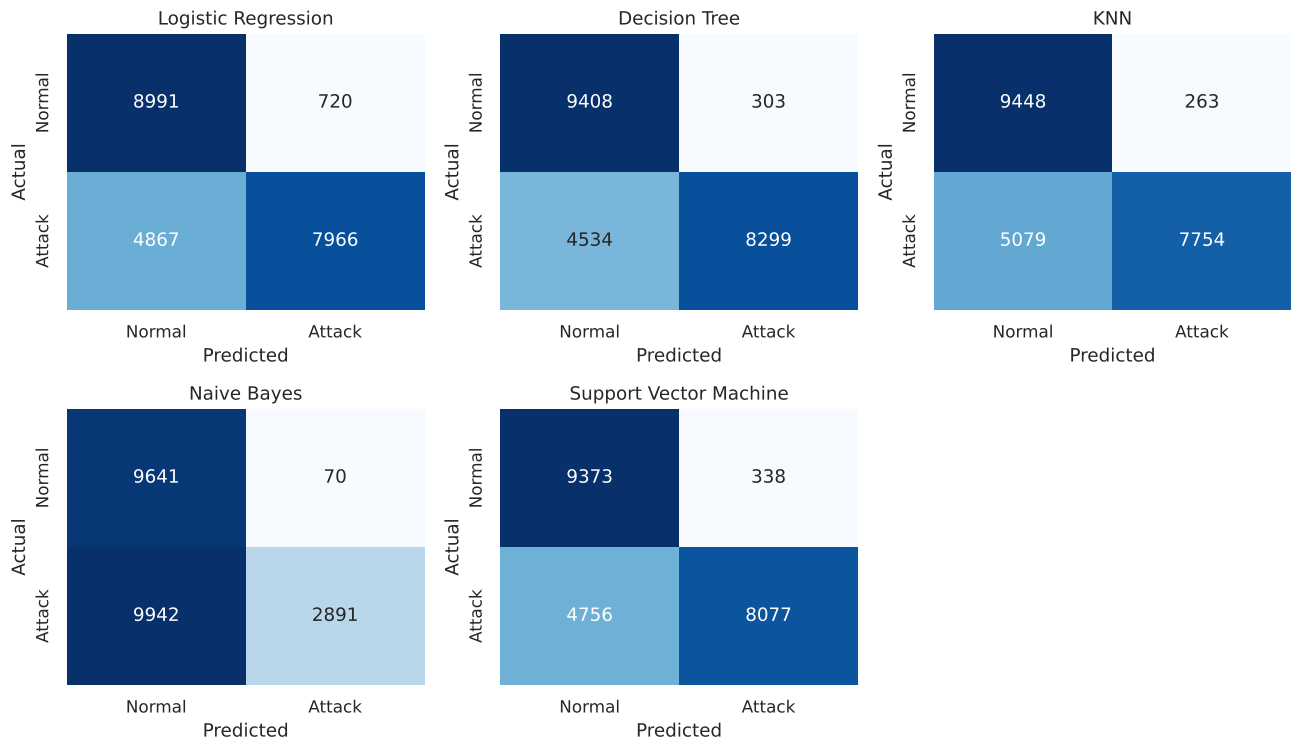

,TN,FP,FN,TP,Attacks missed (%)
Logistic Regression,8991,720,4867,7966,37.9
Decision Tree,9408,303,4534,8299,35.3
KNN,9448,263,5079,7754,39.6
Naive Bayes,9641,70,9942,2891,77.5
Support Vector Machine,9373,338,4756,8077,37.1


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, name in zip(axes.ravel(), models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("figures/confusion_matrices.png", dpi=150); plt.show()

cm_table = pd.DataFrame({n: dict(zip(["TN", "FP", "FN", "TP"], confusion_matrix(y_test, preds[n]).ravel()))
                         for n in models}).T
cm_table["Attacks missed (%)"] = (cm_table["FN"] / (cm_table["FN"] + cm_table["TP"]) * 100).round(1)
cm_table

## 5. Save models and artifacts for the Streamlit app

In [10]:
for name, m in fitted.items():
    joblib.dump(m, f"model/{name.lower().replace(' ', '_')}.joblib", compress=3)
joblib.dump(pre, "model/preprocessor.joblib", compress=3)
results.to_csv("model/metrics.csv", index=False)
test.drop(columns=["target"]).to_csv("test_data.csv", index=False)      # all 22,544 KDDTest+ records
sorted(os.listdir("model"))

['decision_tree.joblib', 'feature_columns.json', 'knn.joblib', 'logistic_regression.joblib', 'metrics.csv', 'naive_bayes.joblib', 'preprocessor.joblib', 'support_vector_machine.joblib']

## 6. Observations

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Accuracy 0.7522 and MCC 0.5562, the lowest of the four reasonable models. As a linear model it cannot capture the non-linear structure of traffic features. It also has the lowest precision (0.9171, 720 false alarms) and misses about 38% of attacks (recall 0.6207). Very fast, and a sensible baseline. |
| **Decision Tree** | Best Accuracy (0.7854), F1 (0.7743) and MCC (0.6274). It fits the training data almost perfectly (depth 21, 231 leaves) yet still generalises best to `KDDTest+`. Precision is high (0.9648, 303 false alarms) and recall is the best among the non-Naive-Bayes models (0.6467). Interpretable, and trains in about two seconds. |
| **KNN** | Accuracy 0.7630, AUC 0.8179, precision 0.9672 (only 263 false alarms), but recall is the lowest after Naive Bayes (0.6042, with 5,079 attacks missed). Trained on a 20,000-row subsample only, and prediction is the slowest because every test record is compared with all stored training points. |
| **Naive Bayes** | Weakest by far: accuracy 0.5559, recall 0.2253, F1 0.3661, MCC 0.3197. It has the highest precision (0.9764, only 70 false alarms) but misses 77% of attacks. Its AUC (0.7989) is higher than its hard predictions suggest, so the ranking is reasonable but the 0.5 threshold is badly placed. The independence and Gaussian assumptions are violated by the strongly correlated rate features and the one-hot columns. |
| **Support Vector Machine** | Best AUC by a wide margin (0.8882), second-best Accuracy (0.7740), F1 (0.7603) and MCC (0.6087), with precision 0.9598. The RBF kernel separates attacks from normal traffic best in ranking terms, even though it was trained on only 20,000 rows; a tuned threshold would likely raise its recall. |

**Overall winner: Decision Tree.** It leads on Accuracy, F1 and MCC (the most balanced single measure here) and is the simplest to explain and the cheapest to run. The **SVM is a close runner-up** and the best model if ranking quality (AUC) matters most.

**Common pattern.** Every model has high precision (0.92 to 0.98) but much lower recall (0.60 to 0.65, except Naive Bayes). This is the known difficulty of `KDDTest+`: its attack mix differs from `KDDTrain+` (the NSL-KDD documentation notes attack types in the test set that are absent from training), so models detect familiar attacks well but miss novel ones. Accuracies around 75% to 79% are typical for this benchmark and should not be compared with the 99% figures often quoted from random splits of the training file.

**Limitations.** Metrics come from a single train/test split with default hyperparameters (no tuning); KNN and SVM use a training subsample; and the test file's binary labels do not allow a per-attack-type breakdown.